# 3. Noise in Image Processing 📸

Before writing OpenCV code, let's understand what image noise is, where it comes from, and how we remove it. These concepts are important in computer vision because noise can affect edge detection, segmentation, feature extraction, and deep learning model performance.

## 1. What is image noise?

An image is made up of pixels, and each pixel stores an intensity or color value. Ideally, these values represent the actual scene. In a real image, however, unwanted variations can appear due to lighting, electronic sensors, transmission, or other factors.

These unwanted variations are called image noise.

Think of noise as unwanted information mixed into the image.

For a grayscale image, we can model it as:

\\[ I\_{\text{noisy}}(x,y)=I\_{\text{original}}(x,y)+N(x,y) \\]

Where:

- \\(I\_{\text{noisy}}(x,y)\\): observed pixel intensity.
- \\(I\_{\text{original}}(x,y)\\): original or ideal pixel intensity.
- \\(N(x,y)\\): noise at that pixel location.
- \\(x,y\\): pixel coordinates.

This is an additive noise model. It works well for some types of noise, such as Gaussian noise, but not every type of image noise follows this model.

### Why does noise matter?

Noise can:

- Hide small details and textures.
- Create false edges.
- Reduce image quality.
- Make thresholding and segmentation less reliable.
- Affect features extracted for machine learning models.

## 2. Gaussian noise

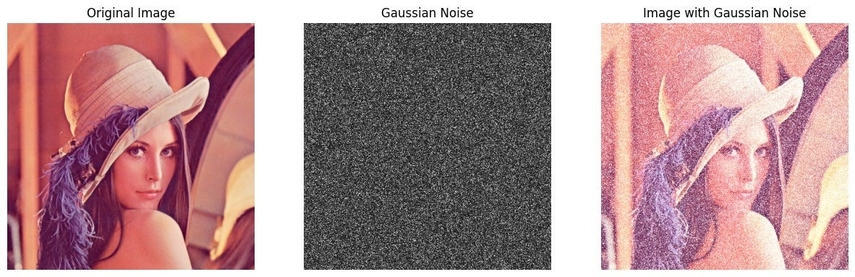

Gaussian noise is random variation whose values approximately follow a normal (Gaussian) probability distribution.


### Intuition

Imagine a pixel that should have an intensity of 120. Due to noise, its measured intensity might become 116, 124, 121, or 112.

The changes are random. Many noise values are close to zero, while larger deviations occur less frequently.

### Mathematical model

\\[ I\_{\text{noisy}}=I\_{\text{original}}+N \\]

The noise variable is modeled as:

\\[ N\sim\mathcal{N}(\mu,\sigma^2) \\]

Where:

- \\(\mu\\): mean of the noise, often assumed to be zero.
- \\(\sigma^2\\): noise variance.
- \\(\sigma\\): standard deviation, which controls the spread of noise values.

For zero-mean noise, the expected noise value is zero. This does not mean that every pixel remains unchanged; individual pixels can become brighter or darker.

### Characteristics

- Appears as fine random grain throughout the image.
- Pixel values may increase or decrease.
- Often modeled as additive noise.
- Can make subtle textures difficult to distinguish.

### Common sources

Gaussian noise is a useful statistical model for certain measurement errors and image acquisition disturbances. Real camera noise is not necessarily purely Gaussian.

## 3. Salt-and-pepper noise

Salt-and-pepper noise introduces random pixels that become extremely bright (salt) or extremely dark (pepper).

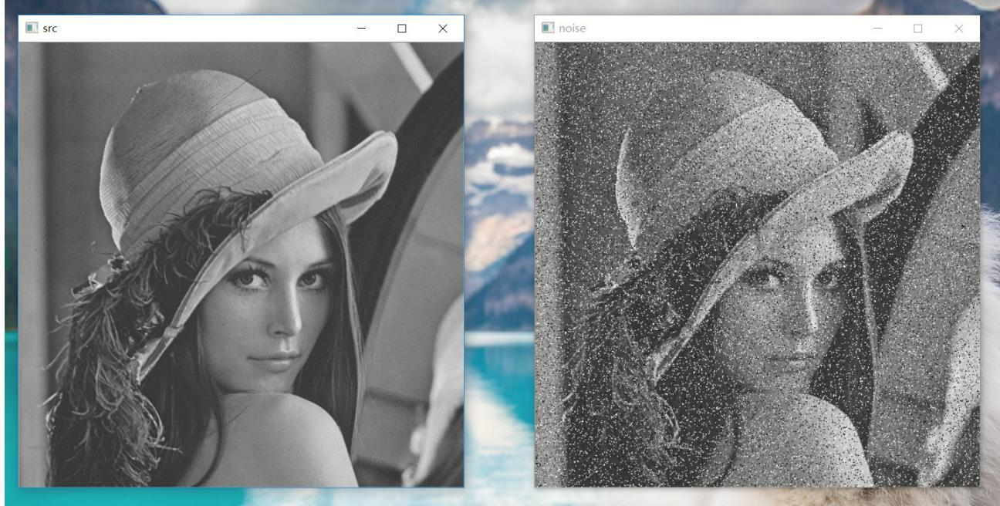

### Intuition

Suppose an image contains a gray pixel with intensity 120. Salt-and-pepper noise might replace it with:

- `255` → a white pixel (salt).
- `0` → a black pixel (pepper).

Unlike Gaussian noise, which usually changes pixel values by varying amounts, salt-and-pepper noise replaces selected pixels with extreme values.

### Mathematical representation

For an 8-bit grayscale image:

\\[ I\_{\text{noisy}}(x,y)= \begin{cases} 255 & \text{with probability }p_s\\\ 0 & \text{with probability }p_p\\\ I\_{\text{original}}(x,y) & \text{otherwise} \end{cases} \\]

Here, \\(p_s\\) is the probability of salt noise and \\(p_p\\) is the probability of pepper noise.

For example, if both probabilities are 0.01, approximately 1% of pixels become white and 1% become black, assuming independent corruption at each pixel.

### Characteristics

- Appears as scattered black and white dots.
- Affects selected pixels rather than necessarily changing every pixel.
- Can damage fine details and edges.
- Is also called impulse noise.

### How is it reduced?

A median filter is particularly effective.

Imagine a neighborhood of nine pixel values:

`[120, 121, 119, 122, 255, 120, 118, 121, 119]`

The median is `120`. The extreme value `255` is rejected by the median operation, so the corrupted pixel can be restored approximately.

The median filter is useful because extreme outliers have much less influence on a median than on an average.

## 4. Sensor noise

Sensor noise originates from the physical process of capturing an image. A camera sensor converts incoming light into electrical signals, and that measurement process introduces uncertainty.

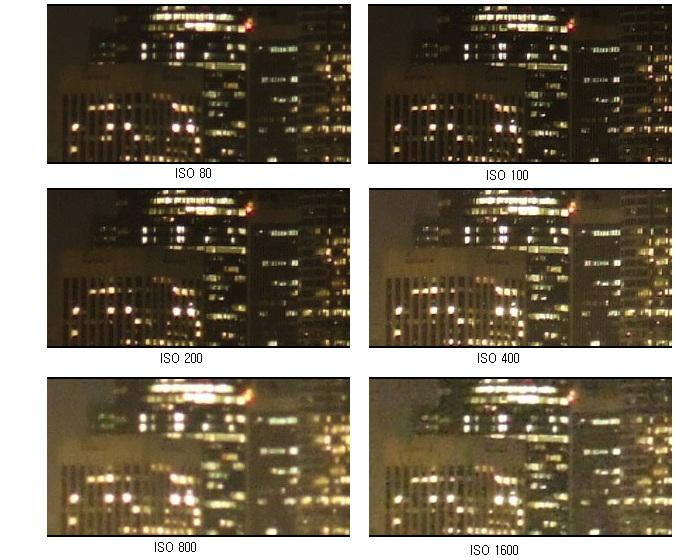

### Major types of sensor noise

1\. Shot noise

- Caused by the random arrival of photons.
- More noticeable when relatively few photons are captured.
- Its standard deviation typically grows with the square root of the expected photon count in a basic photon-counting model.

2\. Read noise

- Introduced when the sensor's electrical signal is read and converted into digital values.
- Comes from electronic components and readout circuitry.

3\. Fixed-pattern noise

- Caused by pixel-to-pixel differences in sensor response or offsets.
- May appear as structured patterns rather than purely random grain.

### Why is noise more visible in low light?

In low light, the sensor receives fewer photons. The useful signal is weaker, so noise can become more noticeable relative to that signal.

Increasing ISO does not itself create additional photons. Depending on the camera, ISO changes amplification and processing, which can make existing noise more visible and affect the final signal-to-noise ratio.

Important distinction: Gaussian noise is a statistical model; sensor noise describes the physical origin of noise. Real sensor noise can combine several components and is not always Gaussian.

## 5. Noise reduction

Noise reduction, also called denoising, attempts to suppress unwanted variations while preserving meaningful image information.

The challenge is that noise and genuine details can look similar. A small texture might be real information, while a small intensity variation might be noise. Removing too much can blur edges and erase details.

### Common noise reduction methods



A. Gaussian filter

Replaces each pixel with a weighted average of nearby pixels. Nearby pixels closer to the center generally receive more weight.

- Useful for reducing fine, random noise.
- Can smooth images effectively.
- May blur edges and small details.



B. Median filter

Replaces a pixel with the median of its neighborhood.

- Particularly useful for salt-and-pepper noise.
- Preserves edges better than a simple averaging filter in many cases.
- Can remove fine textures when the kernel is too large.



C. Bilateral filter

Averages nearby pixels while considering both spatial distance and intensity similarity.

- Smooths similar neighboring regions.
- Often preserves strong edges better than Gaussian smoothing.
- Can be slower than simple filters.



D. Non-local means

Uses similar image patches, including patches farther away, to estimate cleaner pixel values.

- Can preserve repeated textures and details well.
- Often computationally more expensive than simple filters.
- Performance depends on the noise level and parameter settings.

### Which method should you choose?

| Noise type or goal                        | A good starting point |
| ----------------------------------------- | --------------------- |
| Fine Gaussian-like noise                  | Gaussian filter       |
| Salt-and-pepper noise                     | Median filter         |
| Smoothing while preserving edges          | Bilateral filter      |
| More advanced detail-preserving denoising | Non-local means       |

These are starting points, not strict rules. The best method depends on the noise characteristics and how much detail must be preserved.

## 6. The most important concept: Noise vs. blur

These are different problems!

- Noise: Unwanted pixel variations make an image grainy or speckled.
- Blur: Image details and edges become less sharp, often because of motion, defocus, or smoothing.

A denoising filter may reduce noise but introduce blur. Good denoising tries to balance noise suppression with detail preservation.

## 7. How these concepts fit into your computer vision pipeline

Input image

Contains noise

Identify the noise type

Gaussian, impulse, sensor-related

Apply a suitable denoising method

Median, Gaussian, bilateral, etc.

Enhanced image

Less noise, useful details preserved as much as possible

### Quick revision

| Topic                 | Remember this                                                       |
| --------------------- | ------------------------------------------------------------------- |
| Gaussian noise        | Random intensity variations following a Gaussian model              |
| Salt-and-pepper noise | Random black and white pixels                                       |
| Sensor noise          | Noise arising from image acquisition hardware and photon statistics |
| Noise reduction       | Suppress noise while preserving important details                   |

---

# Gaussian Noise 

# 4. Image Filtering — OpenCV

Image filtering modifies pixel values to reduce noise, smooth images, preserve edges, or enhance details.

## 1. Gaussian Filtering

- Smooths an image using a **Gaussian-weighted average** of neighboring pixels.
- Nearby pixels receive higher weights than distant pixels.
- Useful for reducing Gaussian-like noise and minor image variations.
- May blur edges and fine details.

**OpenCV:**
```python
result = cv2.GaussianBlur(img, (5, 5), 0)
```

**Applications:** Noise reduction, preprocessing, and Gaussian pyramids.

## 2. Median Filtering

- Replaces each pixel with the **median** of the pixel values in its neighborhood.
- Particularly effective for salt-and-pepper (impulse) noise.
- Often preserves edges better than mean filtering.
- Large kernels may remove fine details.

**OpenCV:**
```python
result = cv2.medianBlur(img, 5)
```

**Note:** The kernel size must be an odd integer greater than 1.

## 3. Mean Filtering

- Replaces each pixel with the arithmetic average of neighboring pixels.
- Simple and computationally efficient.
- Reduces small intensity variations.
- Can blur edges and fine details because all pixels in the kernel receive equal weights.

**OpenCV:**
```python
result = cv2.blur(img, (5, 5))
```

**Applications:** Basic smoothing and simple noise reduction.

## 4. Bilateral Filtering

- Smooths an image while attempting to preserve strong edges.
- Considers both spatial distance and intensity similarity.
- Pixels that are nearby and have similar intensities receive higher weights.
- Computationally more expensive than simple mean or Gaussian filtering.

**OpenCV:**
```python
result = cv2.bilateralFilter(
    img, 9, 75, 75
)
```

**Parameters:**
- `9`: Diameter of the neighborhood.
- `75`: Color/intensity similarity parameter (`sigmaColor`).
- `75`: Spatial distance parameter (`sigmaSpace`).

**Applications:** Edge-preserving smoothing and image preprocessing.

## 5. Sharpening

- Enhances edges and fine details by increasing local contrast.
- Often uses high-pass filtering or unsharp masking.
- Does not recover information that was never captured.
- Excessive sharpening can amplify noise and create halos.

**OpenCV:**
```python
import numpy as np

kernel = np.array([
    [ 0, -1,  0],
    [-1,  5, -1],
    [ 0, -1,  0]
])

result = cv2.filter2D(img, -1, kernel)
```

**Applications:** Enhancing text, edges, and fine image details.

## 6. Non-Local Means Filtering

- Reduces noise by comparing **similar image patches**, including patches located far apart.
- Assigns higher weights to patches that look more similar.
- Can preserve textures and details better than simple averaging filters.
- Generally more computationally expensive.

**OpenCV (grayscale image):**
```python
result = cv2.fastNlMeansDenoising(
    img,
    None,
    h=10,
    templateWindowSize=7,
    searchWindowSize=21
)
```

**Parameters:**
- `h`: Denoising strength; higher values generally remove more noise but may lose details.
- `templateWindowSize`: Size of the patch being compared.
- `searchWindowSize`: Region searched for similar patches.

**Applications:** Photo denoising and detail-preserving noise reduction.

## 7. Comparison Table

| Filter | Main purpose | Edge preservation | Best starting use |
|---|---|---|---|
| Gaussian | Smooth image | Limited | Gaussian-like noise |
| Median | Remove outliers | Often good | Salt-and-pepper noise |
| Mean | Simple smoothing | Poor | Basic noise reduction |
| Bilateral | Edge-preserving smoothing | Good | Smoothing while retaining boundaries |
| Sharpening | Enhance details | Enhances edges | Improving perceived sharpness |
| Non-Local Means | Patch-based denoising | Often good | Noise reduction with texture preservation |

## 8. Key Takeaways

- **Mean:** Equal-weight averaging of nearby pixels.
- **Gaussian:** Distance-based weighted averaging.
- **Median:** Replaces a pixel with the neighborhood's median.
- **Bilateral:** Combines spatial proximity with intensity similarity.
- **Sharpening:** Enhances local contrast around edges.
- **Non-Local Means:** Averages similar patches using similarity-based weights.

**Important:** No filter is best for every image. Choose the filter according to the noise type, image content, and amount of detail you need to preserve.


In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

image_path = "images/00_image.jpg"

image_bgr = cv2.imread(image_path)

if image_bgr is None:
    raise FileNotFoundError(f"Image not found: {image_path}")

image = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)

print("Shape:", image.shape)
print("Dtype:", image.dtype)

Shape: (2400, 1320, 3)
Dtype: uint8


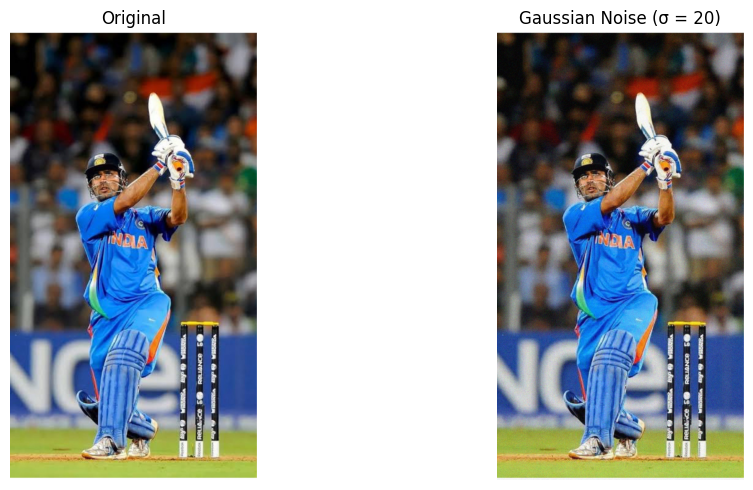

In [2]:
np.random.seed(42)

gaussian_noise = np.random.normal(
    loc=0,
    scale=20,
    size=image.shape
)

noisy_gaussian = np.clip(
    image.astype(np.float32) + gaussian_noise,
    0,
    255
).astype(np.uint8)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(image)
axes[0].set_title("Original")
axes[0].axis("off")

axes[1].imshow(noisy_gaussian)
axes[1].set_title("Gaussian Noise (σ = 20)")
axes[1].axis("off")

plt.tight_layout()
plt.show()

# Salt-and-pepper noise

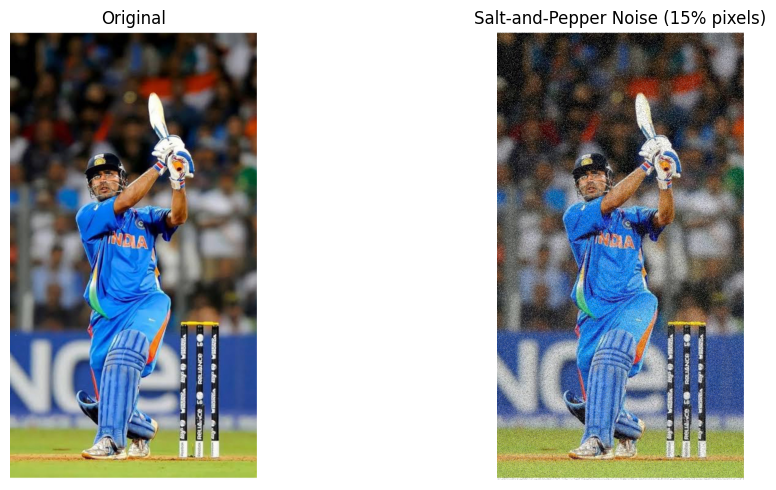

In [3]:
np.random.seed(42)

noisy_sp = image.copy()

noise_fraction = 0.15
random_map = np.random.random(image.shape[:2])

noisy_sp[random_map < noise_fraction / 2] = [0, 0, 0]
noisy_sp[
    (random_map >= noise_fraction / 2) &
    (random_map < noise_fraction)
] = [255, 255, 255]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(image)
axes[0].set_title("Original")
axes[0].axis("off")

axes[1].imshow(noisy_sp)
axes[1].set_title("Salt-and-Pepper Noise (15% pixels)")
axes[1].axis("off")

plt.tight_layout()
plt.show()

In [4]:
random_map

array([[0.37454012, 0.95071431, 0.73199394, ..., 0.73158952, 0.08162998,
        0.06035208],
       [0.24710323, 0.15954468, 0.87178357, ..., 0.76103779, 0.95077271,
        0.7025405 ],
       [0.29805221, 0.10536492, 0.78182386, ..., 0.41962738, 0.05062247,
        0.03939183],
       ...,
       [0.62679717, 0.77392401, 0.21379195, ..., 0.5023549 , 0.22487298,
        0.17592151],
       [0.65522336, 0.52373275, 0.52871718, ..., 0.36426969, 0.74443668,
        0.60872858],
       [0.86980995, 0.57215885, 0.95842808, ..., 0.9429851 , 0.03088157,
        0.03632599]], shape=(2400, 1320))

# Sensor noise simulation

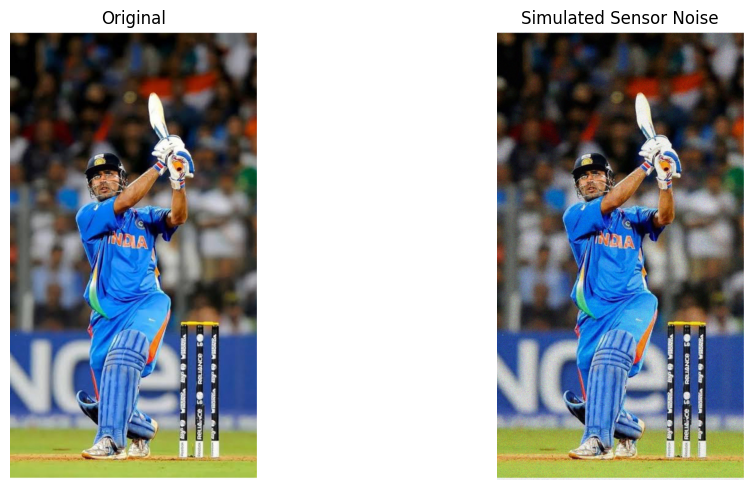

In [5]:
np.random.seed(42)

image_float = image.astype(np.float32)

# Approximate signal-dependent noise
noise_std = 5 + 2.0 * np.sqrt(image_float)
sensor_noise = np.random.normal(0, noise_std, image.shape)

noisy_sensor = np.clip(
    image_float + sensor_noise,
    0,
    255
).astype(np.uint8)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(image)
axes[0].set_title("Original")
axes[0].axis("off")

axes[1].imshow(noisy_sensor)
axes[1].set_title("Simulated Sensor Noise")
axes[1].axis("off")

plt.tight_layout()
plt.show()

# Noise reduction

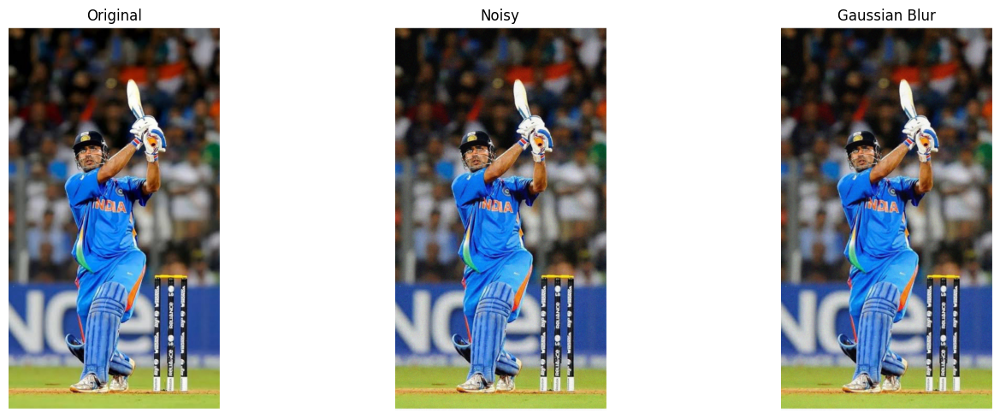

In [6]:
# Gaussian blur

gaussian_denoised = cv2.GaussianBlur(
    noisy_gaussian,
    (5, 5),
    sigmaX=1.0
)

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(image)
plt.title("Original")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(noisy_gaussian)
plt.title("Noisy")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(gaussian_denoised)
plt.title("Gaussian Blur")
plt.axis("off")

plt.tight_layout()
plt.show()

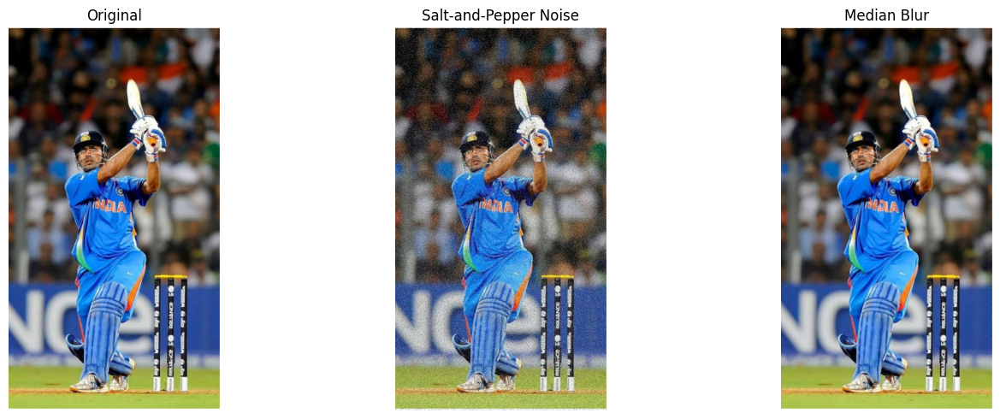

In [7]:
# Median blur

median_denoised = cv2.medianBlur(noisy_sp, 5)

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(image)
plt.title("Original")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(noisy_sp)
plt.title("Salt-and-Pepper Noise")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(median_denoised)
plt.title("Median Blur")
plt.axis("off")

plt.tight_layout()
plt.show()

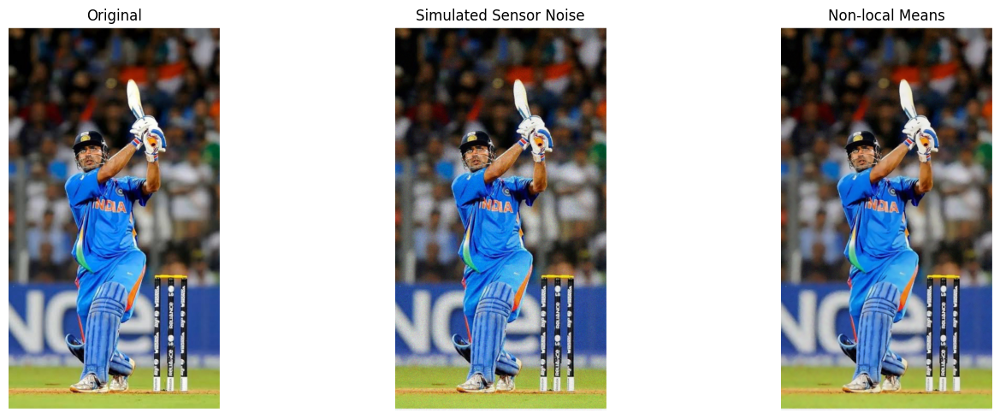

In [8]:
# Non-local means denoising

noisy_sensor_bgr = cv2.cvtColor(
    noisy_sensor,
    cv2.COLOR_RGB2BGR
)

denoised_bgr = cv2.fastNlMeansDenoisingColored(
    noisy_sensor_bgr,
    None,
    h=10,
    hColor=10,
    templateWindowSize=7,
    searchWindowSize=21
)

denoised_rgb = cv2.cvtColor(
    denoised_bgr,
    cv2.COLOR_BGR2RGB
)

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(image)
plt.title("Original")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(noisy_sensor)
plt.title("Simulated Sensor Noise")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(denoised_rgb)
plt.title("Non-local Means")
plt.axis("off")

plt.tight_layout()
plt.show()

# Sharpening

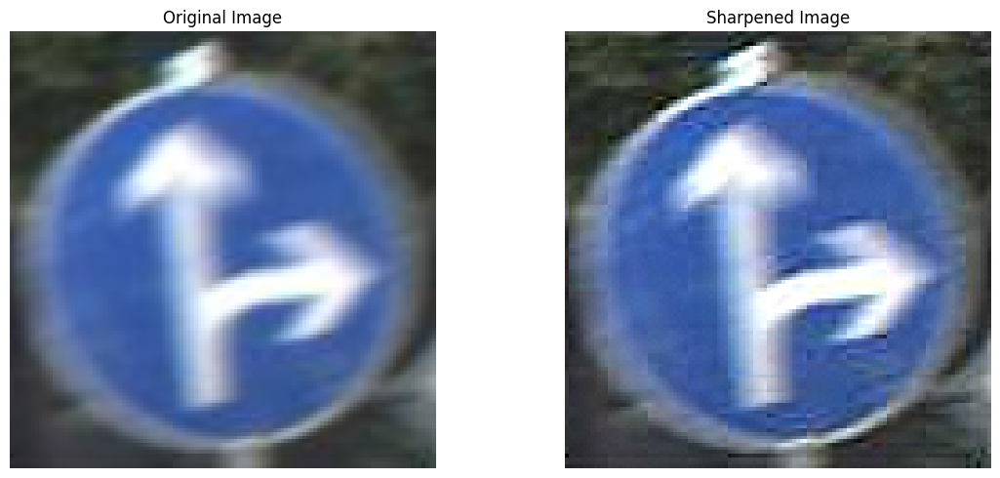

In [10]:
# Read image
img = cv2.imread("images/01_image.png")
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# Sharpening kernel
kernel = np.array([
    [ 0, -1,  0],
    [-1,  5, -1],
    [ 0, -1,  0]
])

# Apply sharpening
sharpened = cv2.filter2D(img, -1, kernel)

# Display results
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(img)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(sharpened)
plt.title("Sharpened Image")
plt.axis("off")

plt.tight_layout()
plt.show()

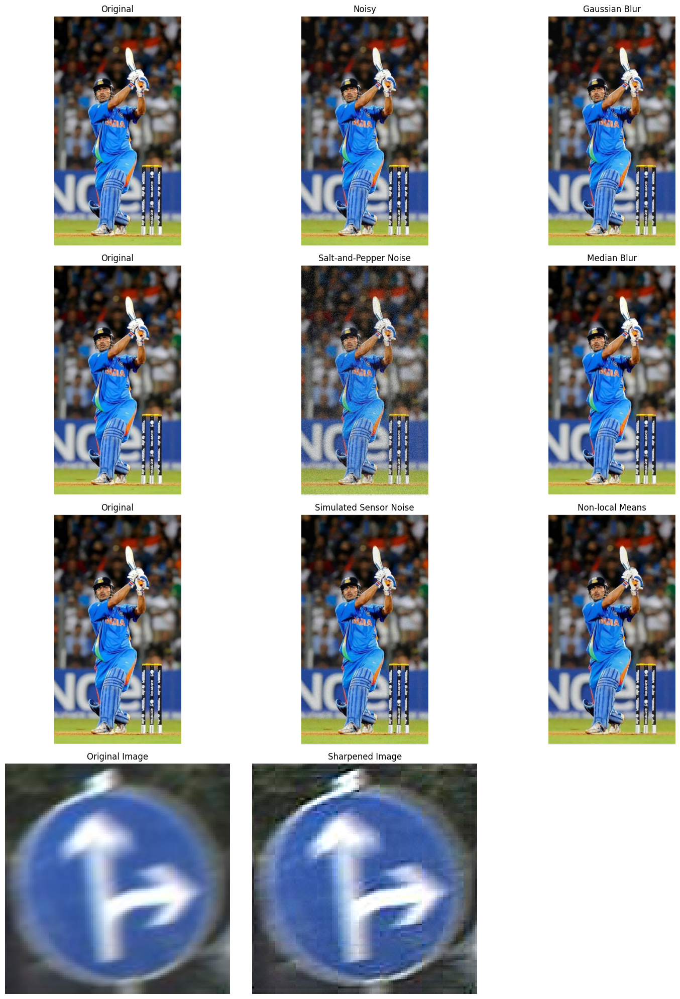

In [11]:
plt.figure(figsize=(15, 20))

plt.subplot(4, 3, 1)
plt.imshow(image)
plt.title("Original")
plt.axis("off")

plt.subplot(4, 3, 2)
plt.imshow(noisy_gaussian)
plt.title("Noisy")
plt.axis("off")

plt.subplot(4, 3, 3)
plt.imshow(gaussian_denoised)
plt.title("Gaussian Blur")
plt.axis("off")

plt.subplot(4, 3, 4)
plt.imshow(image)
plt.title("Original")
plt.axis("off")

plt.subplot(4, 3, 5)
plt.imshow(noisy_sp)
plt.title("Salt-and-Pepper Noise")
plt.axis("off")

plt.subplot(4, 3, 6)
plt.imshow(median_denoised)
plt.title("Median Blur")
plt.axis("off")

plt.subplot(4, 3, 7)
plt.imshow(image)
plt.title("Original")
plt.axis("off")

plt.subplot(4, 3, 8)
plt.imshow(noisy_sensor)
plt.title("Simulated Sensor Noise")
plt.axis("off")

plt.subplot(4, 3, 9)
plt.imshow(denoised_rgb)
plt.title("Non-local Means")
plt.axis("off")

plt.subplot(4, 3, 10)
plt.imshow(img)
plt.title("Original Image")
plt.axis("off")

plt.subplot(4, 3, 11)
plt.imshow(sharpened)
plt.title("Sharpened Image")
plt.axis("off")

plt.tight_layout()

plt.savefig("images/3.Noise.jpg")
plt.show()